# Telecom Customer Churn Prediction Using Logistic Regression

## Objective
To predict customer churn using tenure, contract type, monthly charges and service-related features.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    classification_report, precision_score,
    recall_score, f1_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Data Loading and Preprocessing

Loading, inspecting and preparing the dataset for model training.

In [4]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

display(df.head())
print("Dataset shape (rows, columns):", df.shape)
print("\nDataset information:\n")
df.info()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape (rows, columns): (7043, 21)

Dataset information:

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   s

In [14]:
# Checking missing values and duplicates
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

#Dropping rows with missing values(If Any)
df=df.dropna()

# Checking for duplicate records
print("Duplicates:", df.duplicated().sum())

# Removing Customer ID column
df = df.drop(columns=["customerID"])

# Encoding target variable
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0
Duplicates: 0


In [15]:
# Selecting input features
X = df[[
    "tenure", "Contract", "MonthlyCharges",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]]
y = df["Churn"]

# Converting categorical features into numerical form
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Input features:", X.shape)
print("Target variable:", y.shape)

display(X.head())

Input features: (7043, 21)
Target variable: (7043,)


,tenure,MonthlyCharges,Contract_One year,Contract_Two year,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,...,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes
0,1,29.85,0,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
1,34,56.95,1,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,2,53.85,0,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,45,42.30,1,0,0,1,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
4,2,70.70,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


## 2. Exploratory Data Analysis (EDA)

#Analysing customer churn patterns using graphs and visualizations.

Churn
0    5174
1    1869
Name: count, dtype: int64


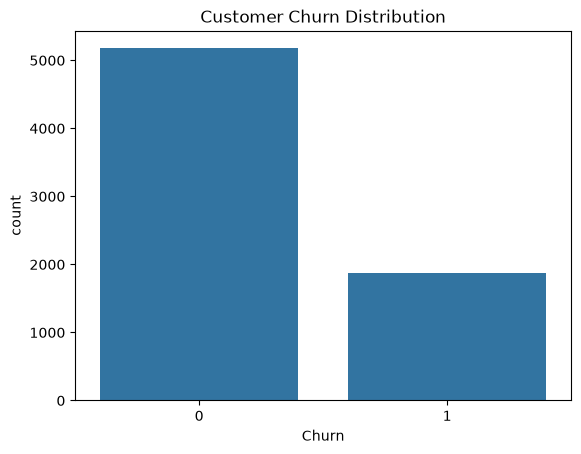

In [16]:
print(df["Churn"].value_counts())

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


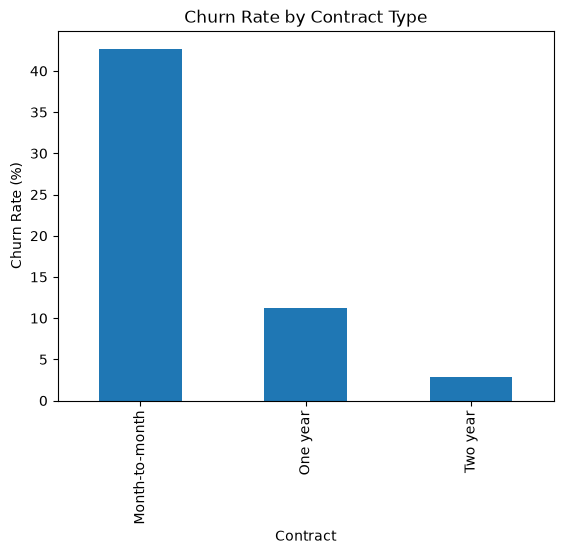

In [17]:
contract_churn = df.groupby("Contract")["Churn"].mean() * 100

print(contract_churn)

contract_churn.plot(kind="bar")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.show()

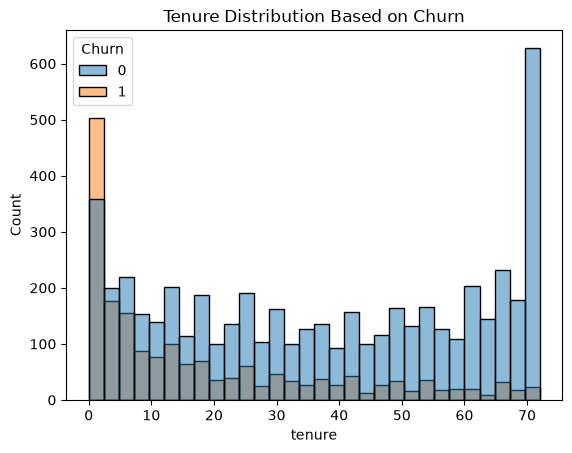

In [18]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Tenure Distribution Based on Churn")
plt.show()

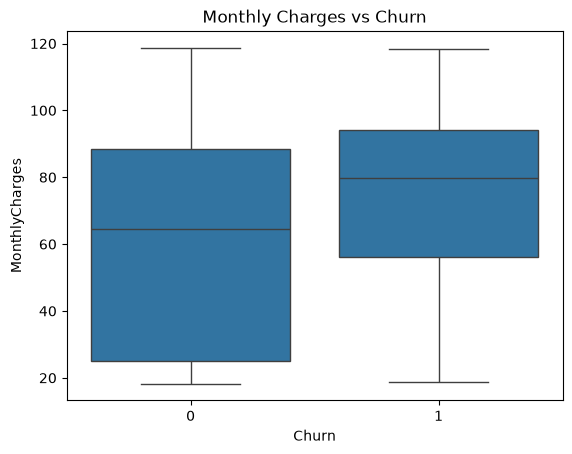

In [19]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

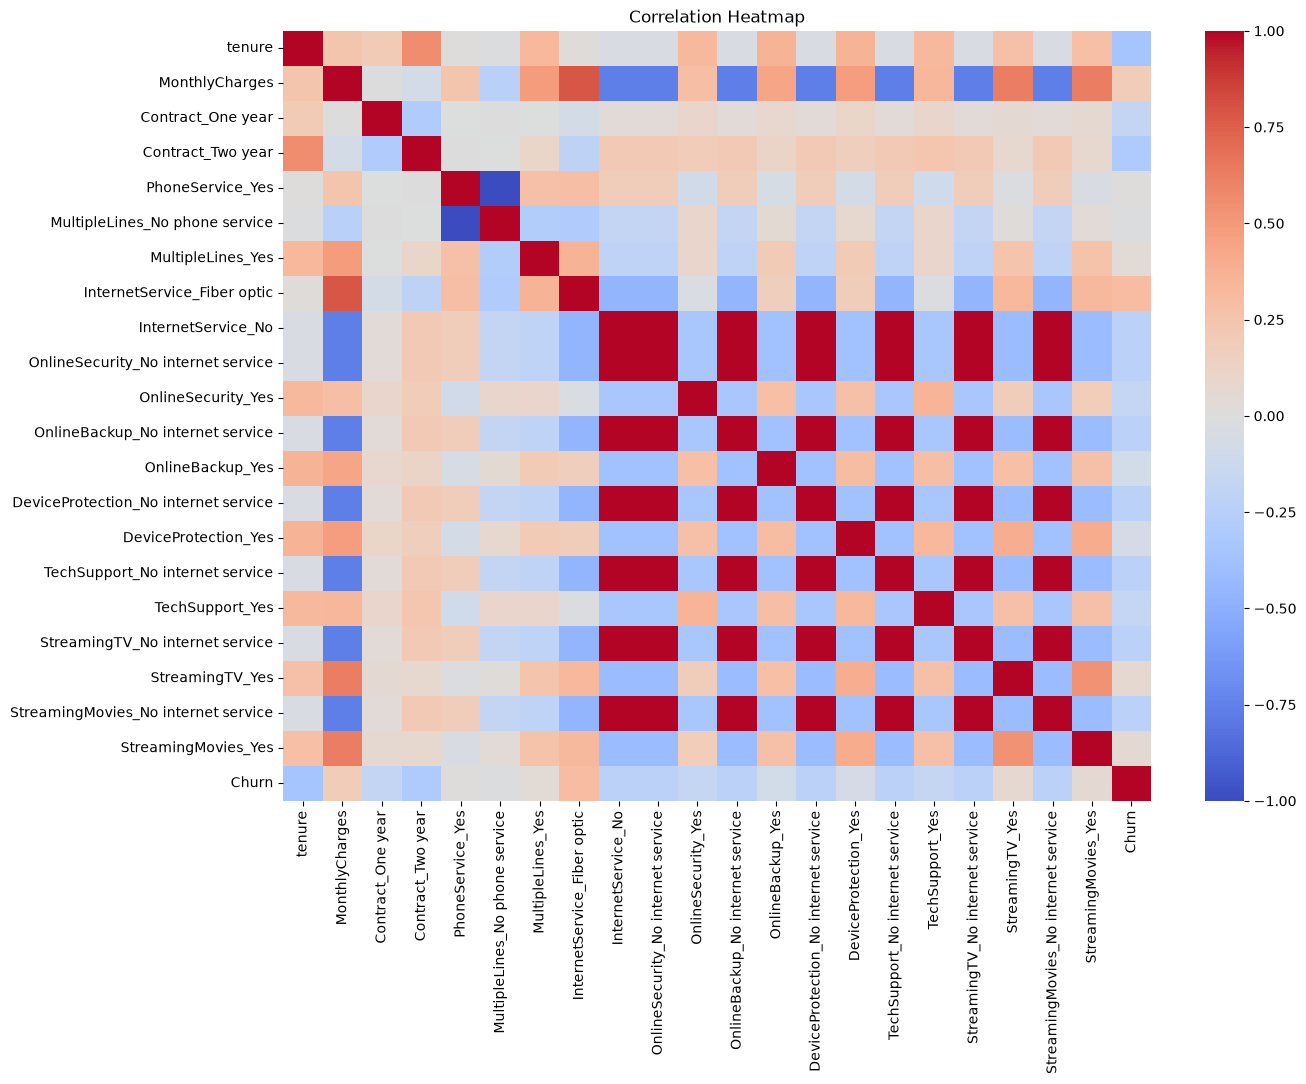

In [20]:
correlation_data = pd.concat([X, y.rename("Churn")], axis=1)

plt.figure(figsize=(14, 10))
sns.heatmap(correlation_data.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## 3. Model Building and Training

Splitting the dataset, standardizing features and training the Logistic Regression model.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5634, 21)
(1409, 21)


In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Model trained successfully")

Model trained successfully


,Feature,Coefficient
0,tenure,-0.816258
1,MonthlyCharges,-0.897150
2,Contract_One year,-0.327782
3,Contract_Two year,-0.649162
4,PhoneService_Yes,0.010974
5,MultipleLines_No phone service,-0.010974
6,MultipleLines_Yes,0.248051
7,InternetService_Fiber optic,0.890879
8,InternetService_No,-0.103076
9,OnlineSecurity_No internet service,-0.103076


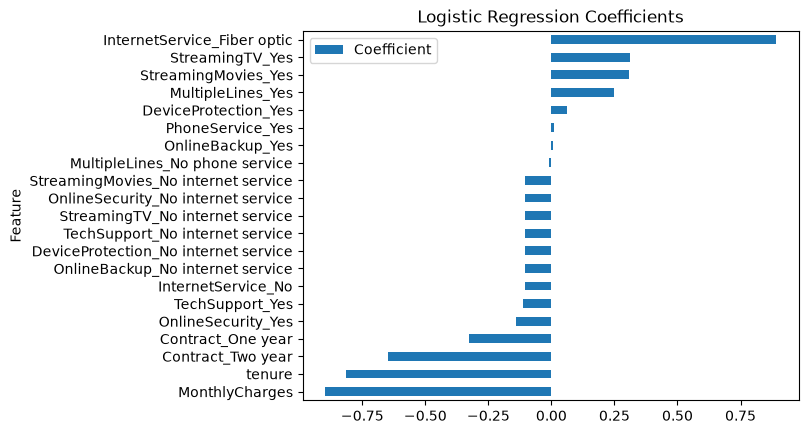

In [24]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

display(coefficients)

coefficients.sort_values(
    by="Coefficient"
).plot(x="Feature", y="Coefficient", kind="barh")

plt.title("Logistic Regression Coefficients")
plt.show()